# Stage 2 calibration of cortical MD perturbation scores

Evaluate leave-one-out (LOO) scores from older cognitively normal (CN) participants before interpreting patient burden. Compare both models on the same finite subject × column × depth entries. Coverage is also shown separately for each model before applying the shared mask.

Run on kea. Run the inventory cell first, then set the filenames in the configuration cell using the Stage 2 outputs. If the run has no roster, use the exact target roster used to write these arrays and confirm its row order against the pipeline. Array shape alone cannot establish row alignment.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import norm

run_dir = Path(
    "/mnt/newStor/paros/paros_WORK/xintong/code/cortical_trajectory_analysis"
    "/analysis_results/figure6_new/outputs/warped_delta_382DBdHx"
)
print("Available score arrays and CSV files")
for path in sorted(run_dir.iterdir()):
    if path.name.endswith(("_z.npy", ".csv")):
        print(path.name)

Available score arrays and CSV files
age_sex_group_effects.csv
age_sex_thickness_group_effects.csv
age_sex_thickness_z.npy
age_sex_z.npy
participants.csv
positions.csv
stage2_burden.csv
stage2_qc.csv


In [4]:
import pandas as pd

print(pd.read_csv(run_dir / "participants.csv", nrows=0).columns.tolist())

['scoring_row_index', 'DX_Label_harmonized', 'Global_Cognition_Composite', 'MOCATOTS', 'PTID', 'PTID_clean', 'QIAL_has_imaging_data', 'QIAL_match_confidence', 'SUBJECT_SEX', 'VISITNUM', 'VISIT_DATE', 'actual_age', 'age_at_scan_source', 'age_diagnosis_complete', 'age_eligible_41_78', 'cn_at_scan', 'coverage_fraction', 'coverage_ge_0_98', 'date_match_primary', 'date_match_primary_or_approved_low', 'diagnosis_at_scan', 'diagnosis_at_scan_source', 'figure5_primary_eligible', 'figure5_sensitivity_eligible', 'figure7_included', 'global_cognition', 'inclusion_exclusion_reason', 'low_multiple_visits_all_cn_included', 'manual_registration_qc_excluded', 'manual_registration_qc_reason', 'matched_visit_date', 'matrix_row_index', 'matrix_source', 'metadata_exclusion_reason', 'metadata_primary_eligible', 'metadata_sensitivity_eligible', 'minimum_coverage', 'moca', 'moca_88_treated_missing', 'model_id', 'model_role', 'n_analysis_vertices', 'n_qial_matched_visits', 'n_valid_columns', 'option3_qc_pass'

,Cohort,N,Minimum age,Maximum age,Mean age,SD age,Median age,Q1 age,Q3 age
0,All selected CN,193,28.0,78.0,58.21,10.38,56.0,51.00,67.00
1,Young CN reference,37,28.0,49.0,44.38,5.56,46.0,44.00,48.00
2,Older CN reference,156,50.0,78.0,61.49,8.35,59.5,54.00,68.00
3,All Stage 1 targets,180,46.0,78.0,61.37,8.56,59.0,54.00,68.25
4,Stage 1 targets: CN,156,50.0,78.0,61.49,8.35,59.5,54.00,68.00
5,Stage 1 targets: MCI,18,46.0,76.0,58.33,9.44,56.5,52.25,62.00
6,Stage 1 targets: AD,6,54.0,78.0,67.50,8.67,69.0,63.00,72.75
7,Targets aged ≥50: CN,156,50.0,78.0,61.49,8.35,59.5,54.00,68.00
8,Targets aged ≥50: MCI,15,50.0,76.0,60.67,8.55,59.0,54.00,65.50
9,Targets aged ≥50: AD,6,54.0,78.0,67.50,8.67,69.0,63.00,72.75


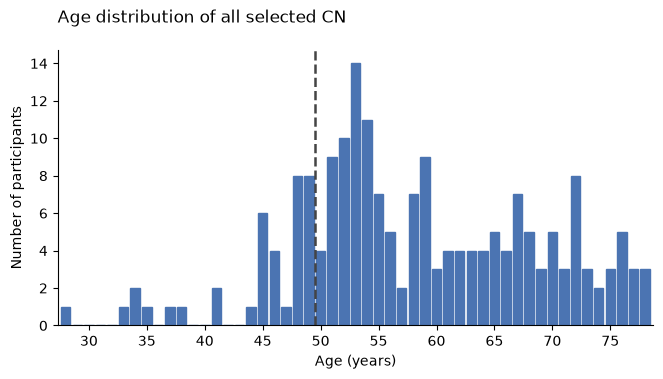

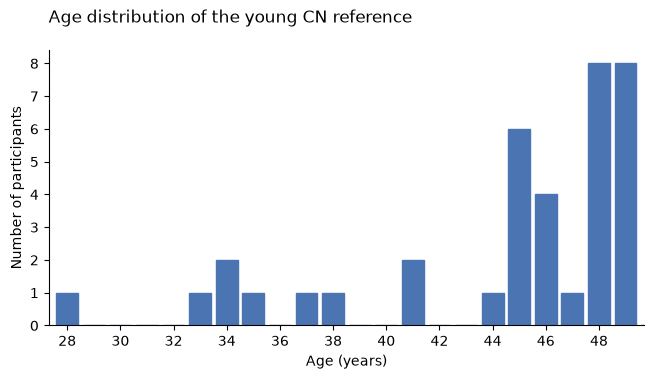

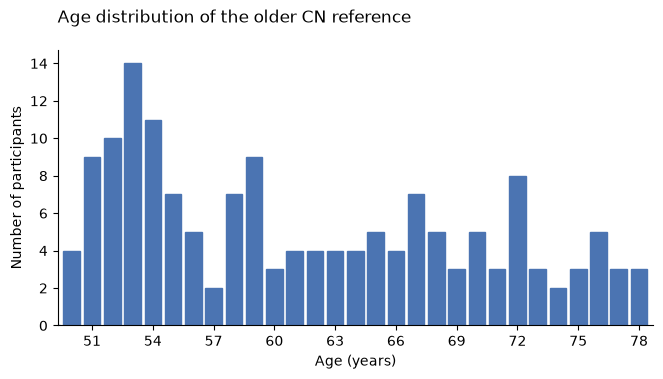

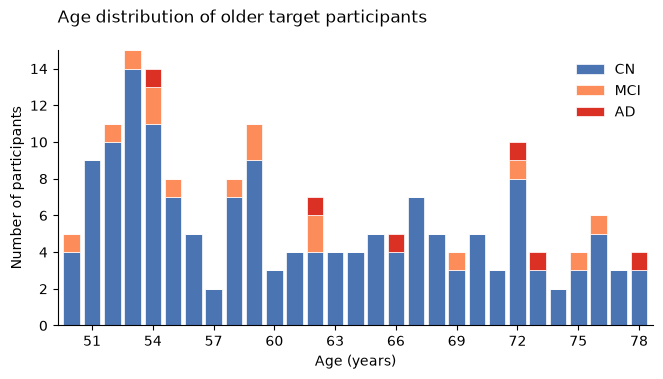

In [28]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.ticker import MaxNLocator

REPO = Path(
    "/mnt/newStor/paros/paros_WORK/xintong/code/cortical_trajectory_analysis"
)
FIGURE6_NEW = REPO / "analysis_results/figure6_new"
RUN = FIGURE6_NEW / "outputs/warped_delta_382DBdHx"

# Confirm this path if the young-reference run used another output directory.
YOUNG_ROSTER = FIGURE6_NEW / "outputs/full/young_reference_roster.csv"
TARGET_ROSTER = RUN / "participants.csv"

COLORS = {
    "Normal": "#4B74B2",
    "MCI": "#FC8C5A",
    "AD": "#DB3124",
    "dark_gray": "#444444",
}
GROUPS = ["Normal", "MCI", "AD"]
GROUP_LABELS = {"Normal": "CN", "MCI": "MCI", "AD": "AD"}

for path in [YOUNG_ROSTER, TARGET_ROSTER]:
    if not path.is_file():
        raise FileNotFoundError(f"Check the roster path: {path}")

young = pd.read_csv(YOUNG_ROSTER, dtype={"subject_id": str})
targets = pd.read_csv(TARGET_ROSTER, dtype={"subject_id": str})

def validate_roster(frame, label):
    required = {"subject_id", "actual_age", "diagnosis_at_scan", "model_role"}
    missing = required - set(frame.columns)
    if missing:
        raise ValueError(f"{label}: missing columns {sorted(missing)}")
    frame = frame.copy()
    frame["age"] = pd.to_numeric(frame["actual_age"], errors="coerce")
    if not np.isfinite(frame["age"]).all():
        raise ValueError(f"{label}: missing or non-finite ages")
    if frame["subject_id"].isna().any() or frame["subject_id"].duplicated().any():
        raise ValueError(f"{label}: missing or duplicate subject IDs")
    return frame

young = validate_roster(young, "Young reference")
targets = validate_roster(targets, "Target cohort")

older_cn = targets.loc[targets["model_role"].eq("older_cn_target")].copy()
all_cn = pd.concat([young, older_cn], ignore_index=True)

assert len(young) == 37
assert len(older_cn) == 156
assert young["diagnosis_at_scan"].eq("Normal").all()
assert older_cn["diagnosis_at_scan"].eq("Normal").all()
assert young["age"].between(28, 49, inclusive="both").all()
assert older_cn["age"].ge(50).all()
assert all_cn["subject_id"].nunique() == len(all_cn)
assert targets["diagnosis_at_scan"].value_counts().to_dict() == {
    "Normal": 156, "MCI": 18, "AD": 6,
}

# Use the same older-age definition for all diagnoses.
older_targets = targets.loc[targets["age"].ge(50)].copy()

def age_summary(frame, label):
    age = frame["age"]
    return {
        "Cohort": label,
        "N": len(frame),
        "Minimum age": age.min(),
        "Maximum age": age.max(),
        "Mean age": age.mean(),
        "SD age": age.std(ddof=1),
        "Median age": age.median(),
        "Q1 age": age.quantile(.25),
        "Q3 age": age.quantile(.75),
    }

summary_rows = [
    age_summary(all_cn, "All selected CN"),
    age_summary(young, "Young CN reference"),
    age_summary(older_cn, "Older CN reference"),
    age_summary(targets, "All Stage 1 targets"),
]
for diagnosis_name in GROUPS:
    summary_rows.append(age_summary(
        targets.loc[targets["diagnosis_at_scan"].eq(diagnosis_name)],
        f"Stage 1 targets: {GROUP_LABELS[diagnosis_name]}",
    ))
for diagnosis_name in GROUPS:
    summary_rows.append(age_summary(
        older_targets.loc[older_targets["diagnosis_at_scan"].eq(diagnosis_name)],
        f"Targets aged ≥50: {GROUP_LABELS[diagnosis_name]}",
    ))

display(pd.DataFrame(summary_rows).round(2))

# Fixed integer-year bins also support fractional ages.
age_min = int(np.floor(all_cn["age"].min()))
age_max = int(np.ceil(max(all_cn["age"].max(), targets["age"].max())))
age_edges = np.arange(age_min, age_max + 2)
age_years = age_edges[:-1]

def counts_by_year(frame):
    return np.histogram(frame["age"], bins=age_edges)[0]

def clean_age_axis(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=12))
    ax.set_ylim(bottom=0)
    ax.set_xlabel("Age (years)")
    ax.set_ylabel("Number of participants")
    ax.tick_params(direction="out")

def single_age_plot(frame, color, title, boundary=False):
    counts = counts_by_year(frame)
    fig, ax = plt.subplots(figsize=(7.09, 4.3))
    ax.bar(age_years, counts, width=.82, color=color,
           edgecolor=color, linewidth=1)
    if boundary:
        # Separate integer ages 49 and 50.
        ax.axvline(49.5, color=COLORS["dark_gray"],
                   linewidth=1.8, linestyle="--")
    clean_age_axis(ax)
    ax.set_title(title, loc="left", pad=20)
    ax.set_xlim(
        np.floor(frame["age"].min()) - .7,
        np.floor(frame["age"].max()) + .7,
    )
    fig.subplots_adjust(left=.13, right=.97, bottom=.16, top=.80)
    plt.show()

# 1. All selected CN, with the young/older boundary only.
single_age_plot(
    all_cn, COLORS["Normal"],
    "Age distribution of all selected CN",
    boundary=True,
)

# 2. Young CN reference.
single_age_plot(
    young, COLORS["Normal"],
    "Age distribution of the young CN reference",
)

# 3. Older CN reference.
single_age_plot(
    older_cn, COLORS["Normal"],
    "Age distribution of the older CN reference",
)
# 4. Stacked age distributions for older target participants.
fig, ax = plt.subplots(figsize=(7.09, 4.3))
bottom = np.zeros(len(age_years), dtype=int)

for diagnosis_name in GROUPS:
    cohort = older_targets.loc[
        older_targets["diagnosis_at_scan"].eq(diagnosis_name)
    ]
    counts = counts_by_year(cohort)

    ax.bar(
        age_years,
        counts,
        bottom=bottom,
        width=.82,
        color=COLORS[diagnosis_name],
        edgecolor="white",
        linewidth=.5,
        label=GROUP_LABELS[diagnosis_name],
    )
    bottom += counts

clean_age_axis(ax)
ax.set_xlim(
    np.floor(older_targets["age"].min()) - .7,
    np.floor(older_targets["age"].max()) + .7,
)
ax.set_title(
    "Age distribution of older target participants",
    loc="left", pad=20,
)
ax.legend(frameon=False)
fig.subplots_adjust(left=.13, right=.97, bottom=.16, top=.80)
plt.show()


In [6]:
# Set these filenames from the inventory above. Absolute paths also work.
score_files = {
    "Age + sex + thickness": "age_sex_thickness_z.npy",
    "Age + sex": "age_sex_z.npy",
}
roster_file = "participants.csv"
row_column = "scoring_row_index"
role_column = "model_role"
older_cn_label = "older_cn_target"

if not all(score_files.values()) or len(set(score_files.values())) != 2:
    raise ValueError("Set both distinct Stage 2 score filenames in score_files.")

roster = pd.read_csv(run_dir / roster_file).sort_values(row_column)
if not np.array_equal(roster[row_column].to_numpy(), np.arange(180)):
    raise ValueError("Expected a complete zero-based scoring row index for 180 targets.")
cn_rows = roster[role_column].eq(older_cn_label).to_numpy()
if cn_rows.sum() != 156:
    raise ValueError("Expected 156 older CN target rows. Check the roster and role label.")

scores = {}
for model, filename in score_files.items():
    array = np.load(run_dir / filename, mmap_mode="r", allow_pickle=False)
    if array.shape not in {(180, 4687, 21), (180, 4687 * 21)}:
        raise ValueError(f"Unexpected score shape for {model}: {array.shape}")
    # The flattened representation must be column-major in feature ordering,
    # with consecutive depths within each column.
    scores[model] = array.reshape(180, 4687, 21)[cn_rows]

bands = {
    "Outer cortex": slice(0, 7),
    "Middle cortex": slice(7, 14),
    "Inner cortex": slice(14, 21),
    "All depths": slice(None),
}
finite = {model: np.isfinite(z) for model, z in scores.items()}
shared = np.logical_and.reduce(list(finite.values()))
colors = dict(zip(scores, ["#275D80", "#BA7041"]))

## Valid score coverage

Each point represents one older CN participant. Coverage uses all planned column-depth entries in each band as the denominator.

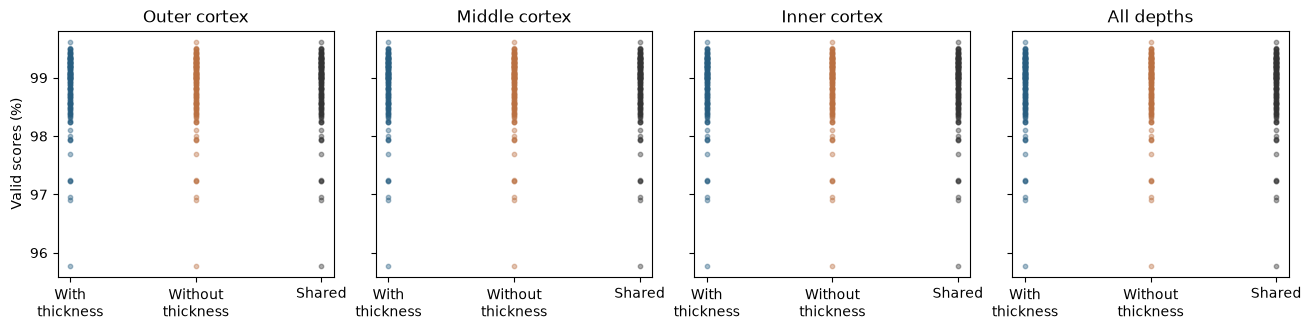

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2), sharey=True, layout="constrained")
for ax, (band, depths) in zip(axes, bands.items()):
    for i, (model, mask) in enumerate(finite.items()):
        coverage = 100 * mask[:, :, depths].mean(axis=(1, 2))
        ax.scatter(np.full(coverage.size, i), coverage, s=10, alpha=.4,
                   color=colors[model], label=model)
    coverage = 100 * shared[:, :, depths].mean(axis=(1, 2))
    ax.scatter(np.full(coverage.size, 2), coverage, s=10, alpha=.4, color="#333333")
    ax.set_xticks([0, 1, 2], ["With\nthickness", "Without\nthickness", "Shared"])
    ax.set_title(band)
axes[0].set_ylabel("Valid scores (%)")
plt.show()

## Z-score distributions

Histograms show the central range. Density uses the full finite sample as the denominator. Q–Q plots include quantiles from 0.01% to 99.99%.

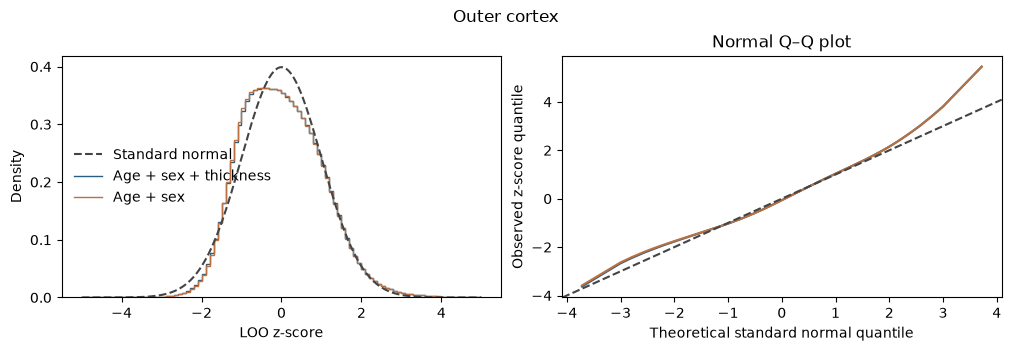

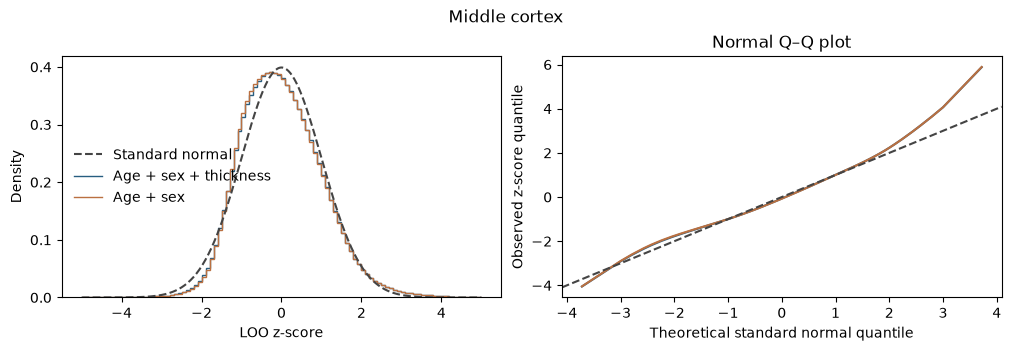

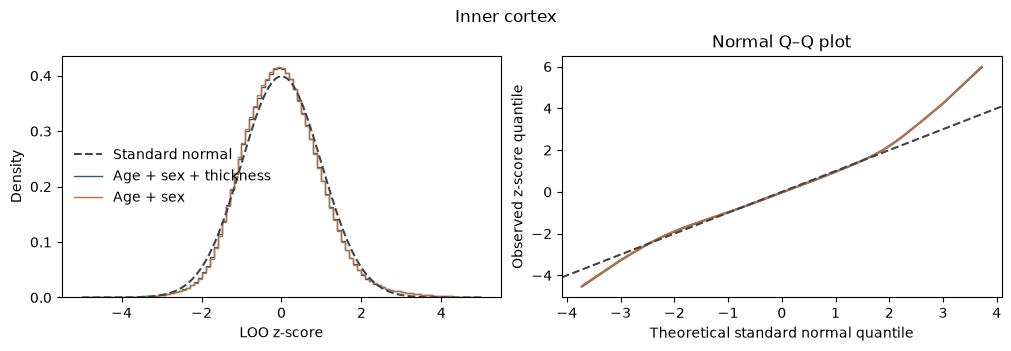

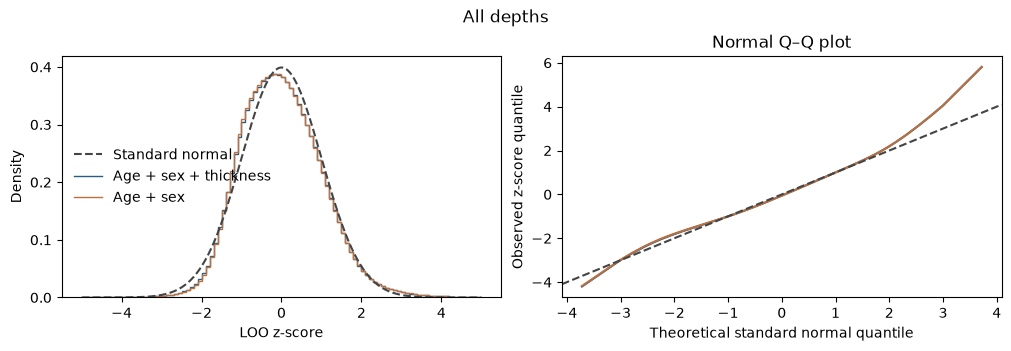

In [8]:
probabilities = np.unique(np.r_[np.linspace(.0001, .9999, 401),
                               norm.cdf([-3, -2, 2, 3])])
theoretical = norm.ppf(probabilities)
bins = np.linspace(-5, 5, 101)
grid = np.linspace(-5, 5, 401)
summary = []
burdens = {}

for band, depths in bands.items():
    mask = shared[:, :, depths]
    denominators = mask.sum(axis=(1, 2))
    if not mask.any():
        print(f"No shared finite scores for {band}.")
        continue
    fig, (hist, qq) = plt.subplots(1, 2, figsize=(10, 3.4), layout="constrained")
    fig.suptitle(band)
    hist.plot(grid, norm.pdf(grid), "--", color="#444444", label="Standard normal")
    for model, array in scores.items():
        band_scores = array[:, :, depths]
        pooled = band_scores[mask]
        counts, _ = np.histogram(pooled, bins)
        hist.stairs(counts / (pooled.size * np.diff(bins)), bins,
                    color=colors[model], label=model)
        qq.plot(theoretical, np.quantile(pooled, probabilities), color=colors[model])
        low = pooled < -2
        high = pooled > 2
        summary.append({
            "Depth band": band, "Model": model, "Valid scores": pooled.size,
            "Mean z": pooled.mean(dtype=np.float64), "Median z": np.median(pooled),
            "SD of z": pooled.std(ddof=1, dtype=np.float64),
            "Coverage within ±1 (%)": 100 * np.mean(np.abs(pooled) <= 1),
            "Coverage within ±2 (%)": 100 * np.mean(~(low | high)),
            "Coverage within ±3 (%)": 100 * np.mean(np.abs(pooled) <= 3),
            "Lower tail, z < −2 (%)": 100 * low.mean(),
            "Upper tail, z > 2 (%)": 100 * high.mean(),
        })
        outliers = (mask & (np.abs(band_scores) > 2)).sum(axis=(1, 2))
        keep = denominators > 0
        burdens[band, model] = 100 * outliers[keep] / denominators[keep]
    hist.set(xlabel="LOO z-score", ylabel="Density")
    hist.legend(frameon=False)
    qq.axline((0, 0), slope=1, ls="--", color="#444444")
    qq.set(xlabel="Theoretical standard normal quantile",
           ylabel="Observed z-score quantile", title="Normal Q–Q plot")
    plt.show()

qc = pd.DataFrame(summary)
if qc.empty:
    raise ValueError("The two models have no shared finite older CN scores.")

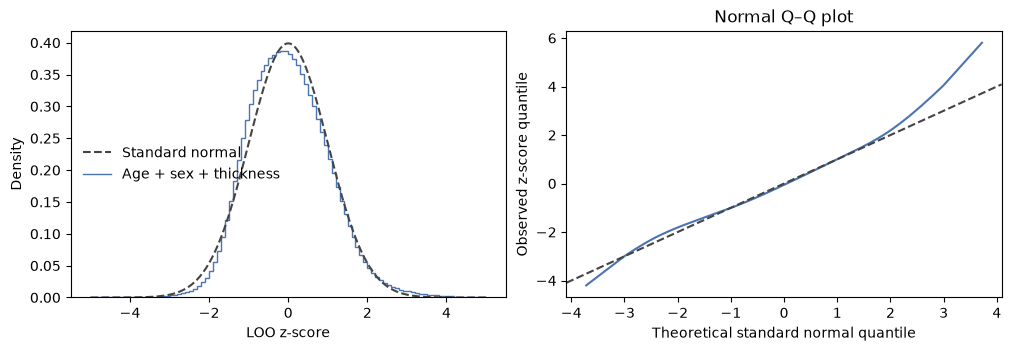

In [14]:
# Standalone distribution and Q–Q plot: thickness-adjusted model.
# Load inputs independently; retain shared finite older-CN entries.
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

model = "Age + sex + thickness"
import pandas as pd
standalone_run = Path('/mnt/newStor/paros/paros_WORK/xintong/code/cortical_trajectory_analysis/analysis_results/figure6_new/outputs/warped_delta_382DBdHx')
standalone_roster = pd.read_csv(standalone_run / 'participants.csv')
standalone_cn = standalone_roster.loc[standalone_roster.model_role.eq('older_cn_target')]
assert len(standalone_cn) == standalone_cn.subject_id.nunique() == 156
standalone_rows = standalone_cn.scoring_row_index.to_numpy(dtype=int)
standalone_arrays = []
for filename in ('age_sex_thickness_z.npy', 'age_sex_z.npy'):
    array = np.load(standalone_run / filename, mmap_mode='r', allow_pickle=False)
    if array.shape not in ((180, 4687, 21), (180, 98427)):
        raise ValueError(f'Unexpected score shape: {array.shape}')
    standalone_arrays.append(array.reshape(180, 4687, 21)[standalone_rows])
standalone_shared = np.isfinite(standalone_arrays[0]) & np.isfinite(standalone_arrays[1])
pooled_thickness = standalone_arrays[0][standalone_shared]
if not pooled_thickness.size:
    raise ValueError("No shared finite older CN scores.")
probabilities_single = np.unique(np.r_[np.linspace(.0001, .9999, 401), norm.cdf([-3, -2, 2, 3])])
bins_single = np.linspace(-5, 5, 101)
grid_single = np.linspace(-5, 5, 401)
fig_thickness, (hist_single, qq_single) = plt.subplots(1, 2, figsize=(10, 3.4), layout="constrained")
hist_single.plot(grid_single, norm.pdf(grid_single), "--", color="#444444", label="Standard normal")
counts_single, _ = np.histogram(pooled_thickness, bins_single)
hist_single.stairs(counts_single / (pooled_thickness.size * np.diff(bins_single)), bins_single,
                   color="#4B74B2", label=model)
hist_single.set(xlabel="LOO z-score", ylabel="Density")
hist_single.legend(frameon=False, loc='upper left', fontsize=9)
qq_single.plot(norm.ppf(probabilities_single), np.quantile(pooled_thickness, probabilities_single), color="#4B74B2")
qq_single.axline((0, 0), slope=1, ls="--", color="#444444")
qq_single.set(xlabel="Theoretical standard normal quantile", ylabel="Observed z-score quantile", title="Normal Q–Q plot")
standalone_dir = standalone_run / "calibration_figures"
standalone_dir.mkdir(parents=True, exist_ok=True)
for extension in ("png", "pdf"):
    fig_thickness.savefig(standalone_dir / f"stage2_thickness_distribution_qq.{extension}", dpi=300, bbox_inches="tight")
plt.show()


## Center and spread

Standard normal reference values are mean 0, median 0, and SD 1.

In [9]:
keys = ["Depth band", "Model"]
display(qc[keys + ["Valid scores", "Mean z", "Median z", "SD of z"]].round(4))

,Depth band,Model,Valid scores,Mean z,Median z,SD of z
0,Outer cortex,Age + sex + thickness,5059481,0.0012,-0.0628,1.0207
1,Outer cortex,Age + sex,5059481,0.0014,-0.0654,1.0173
2,Middle cortex,Age + sex + thickness,5059481,0.0018,-0.0703,1.0227
3,Middle cortex,Age + sex,5059481,0.0017,-0.0744,1.0193
4,Inner cortex,Age + sex + thickness,5059481,0.0015,-0.0334,1.0242
5,Inner cortex,Age + sex,5059481,0.0014,-0.0370,1.0206
6,All depths,Age + sex + thickness,15178443,0.0015,-0.0548,1.0226
7,All depths,Age + sex,15178443,0.0015,-0.0582,1.0191


## Empirical coverage and tails

The dashed line in each panel gives the standard normal reference. These are descriptive comparisons because scores from the same participant and nearby cortical locations are correlated.

,Depth band,Model,Coverage within ±1 (%),Coverage within ±2 (%),Coverage within ±3 (%),"Lower tail, z < −2 (%)","Upper tail, z > 2 (%)"
0,Outer cortex,Age + sex + thickness,66.493,95.915,99.428,1.096,2.989
1,Outer cortex,Age + sex,66.624,96.008,99.433,0.998,2.994
2,Middle cortex,Age + sex + thickness,68.174,95.517,99.180,1.216,3.267
3,Middle cortex,Age + sex,68.336,95.595,99.185,1.136,3.269
4,Inner cortex,Age + sex + thickness,69.723,95.145,98.982,1.828,3.027
5,Inner cortex,Age + sex,69.953,95.197,98.987,1.768,3.035
6,All depths,Age + sex + thickness,68.130,95.526,99.197,1.380,3.094
7,All depths,Age + sex,68.304,95.600,99.202,1.301,3.099


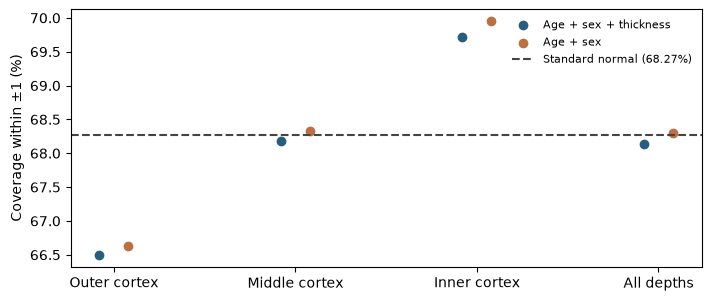

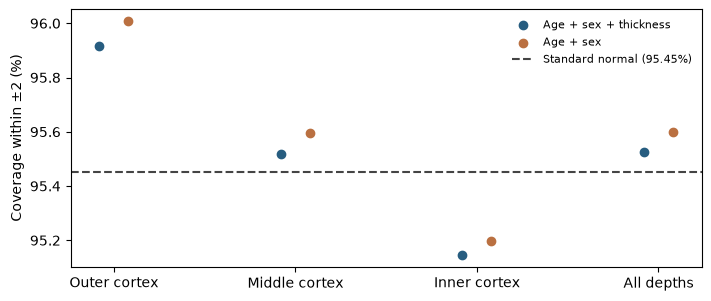

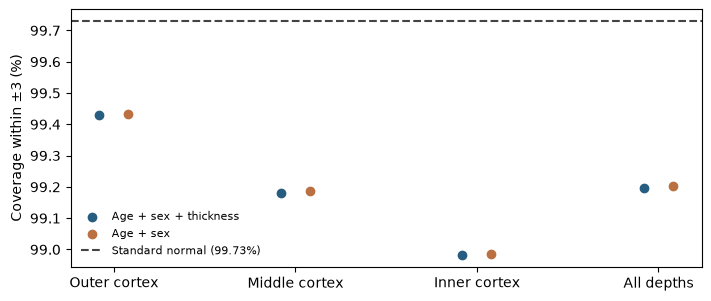

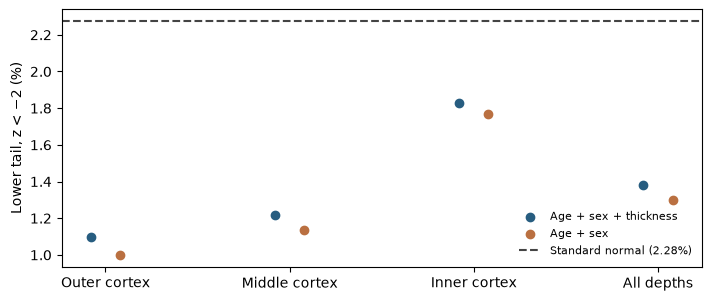

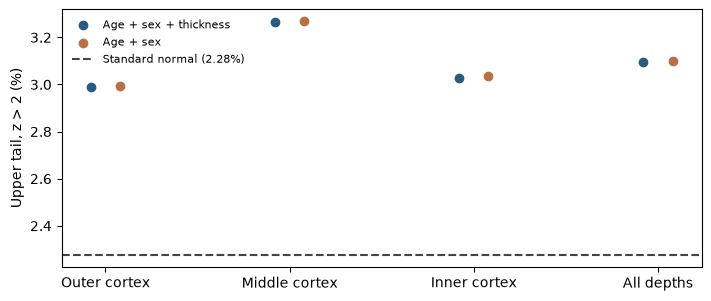

In [10]:
references = {
    **{f"Coverage within ±{k} (%)": 100 * (2 * norm.cdf(k) - 1) for k in (1, 2, 3)},
    "Lower tail, z < −2 (%)": 100 * norm.sf(2),
    "Upper tail, z > 2 (%)": 100 * norm.sf(2),
}
display(qc[keys + list(references)].round(3))
for metric, reference in references.items():
    fig, ax = plt.subplots(figsize=(7, 2.9), layout="constrained")
    for i, model in enumerate(scores):
        values = qc[qc["Model"].eq(model)].set_index("Depth band")[metric]
        ax.scatter(np.arange(len(bands)) + (i - .5) * .16,
                   values.reindex(bands), color=colors[model], label=model)
    ax.axhline(reference, color="#444444", ls="--",
               label=f"Standard normal ({reference:.2f}%)")
    ax.set_xticks(range(len(bands)), list(bands))
    ax.set_ylabel(metric)
    ax.legend(frameon=False, fontsize=8)
    plt.show()

## Subject-level outlier burden

Each point is one older CN participant. The denominator is the number of shared finite scores for that participant and depth band.

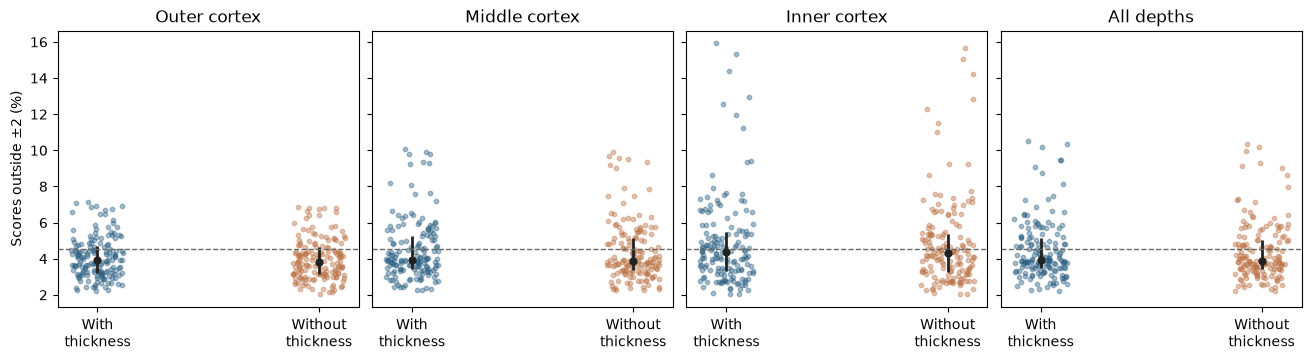

,Depth band,Model,Participants scored,Median valid scores,Burden Q1 (%),Median burden (%),Burden Q3 (%)
0,Outer cortex,Age + sex + thickness,156,32483.5,3.238,3.933,4.725
1,Outer cortex,Age + sex,156,32483.5,3.162,3.831,4.641
2,Middle cortex,Age + sex + thickness,156,32483.5,3.452,3.956,5.242
3,Middle cortex,Age + sex,156,32483.5,3.376,3.887,5.141
4,Inner cortex,Age + sex + thickness,156,32483.5,3.329,4.362,5.454
5,Inner cortex,Age + sex,156,32483.5,3.257,4.299,5.395
6,All depths,Age + sex + thickness,156,97450.5,3.468,3.943,5.171
7,All depths,Age + sex,156,97450.5,3.422,3.875,5.037


In [11]:
rows = []
rng = np.random.default_rng(42)
fig, axes = plt.subplots(1, 4, figsize=(13, 3.5), sharey=True, layout="constrained")
for ax, (band, depths) in zip(axes, bands.items()):
    n_valid = shared[:, :, depths].sum(axis=(1, 2))
    for i, model in enumerate(scores):
        values = burdens.get((band, model), np.array([]))
        if not values.size:
            continue
        q1, median, q3 = np.percentile(values, [25, 50, 75])
        ax.scatter(i + rng.uniform(-.12, .12, size=values.size), values,
                   s=10, alpha=.4, color=colors[model])
        ax.vlines(i, q1, q3, color="#222222", linewidth=2)
        ax.scatter(i, median, color="#222222", s=24, zorder=3)
        rows.append({"Depth band": band, "Model": model,
                     "Participants scored": values.size,
                     "Median valid scores": np.median(n_valid[n_valid > 0]),
                     "Burden Q1 (%)": q1, "Median burden (%)": median,
                     "Burden Q3 (%)": q3})
    ax.axhline(200 * norm.sf(2), ls="--", color="#666666", linewidth=1)
    ax.set_xticks([0, 1], ["With\nthickness", "Without\nthickness"])
    ax.set_title(band)
axes[0].set_ylabel("Scores outside ±2 (%)")
plt.show()
display(pd.DataFrame(rows).round(3))

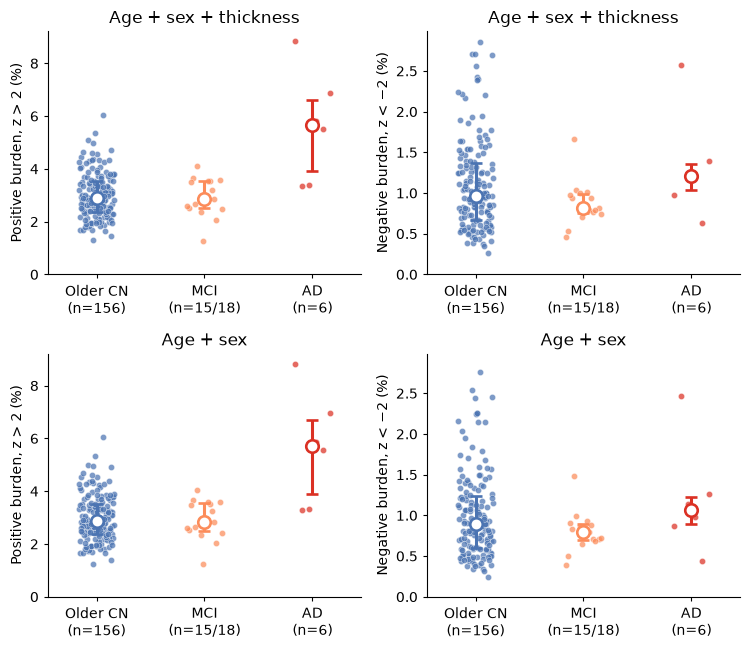

In [14]:
# Standalone legacy outer-layer directional plot (fixed ±2).
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
directional_run = Path('/mnt/newStor/paros/paros_WORK/xintong/code/cortical_trajectory_analysis/analysis_results/figure6_new/outputs/warped_delta_382DBdHx')
directional_roster = pd.read_csv(directional_run / 'participants.csv').sort_values('scoring_row_index').reset_index(drop=True)
assert np.array_equal(directional_roster.scoring_row_index.to_numpy(), np.arange(180))
directional_groups = directional_roster.diagnosis_at_scan.astype('string').str.strip().str.upper().map({'NORMAL':'Older CN', 'CN':'Older CN', 'MCI':'MCI', 'AD':'AD'})
directional_arrays = {label: np.load(directional_run / filename, mmap_mode='r', allow_pickle=False).reshape(180, 4687, 21)[:, :, :7] for label, filename in [('Age + sex + thickness', 'age_sex_thickness_z.npy'), ('Age + sex', 'age_sex_z.npy')]}
directional_shared = np.logical_and.reduce([np.isfinite(a) for a in directional_arrays.values()])
directional_denominator = directional_shared.sum(axis=(1,2))
directional_tables = []
for label, array in directional_arrays.items():
    table = pd.DataFrame({'Group': directional_groups, 'Model': label})
    for metric, exceeds in [('Positive burden (%)', array > 2), ('Negative burden (%)', array < -2)]:
        table[metric] = np.divide(100. * (directional_shared & exceeds).sum(axis=(1,2)), directional_denominator, out=np.full(180, np.nan), where=directional_denominator > 0)
    directional_tables.append(table)
burden = pd.concat(directional_tables, ignore_index=True)
rng = np.random.default_rng(20261111)
group_order = ["Older CN", "MCI", "AD"]
model_order = ["Age + sex + thickness", "Age + sex"]
panel_specs = [
    ("Positive burden (%)", "Positive burden, z > 2 (%)"),
    ("Negative burden (%)", "Negative burden, z < −2 (%)"),
]

# Reuse the Figure 7A palette when it is available in this notebook.
palette = globals().get("group_colors", {})
plot_colors = {
    "Older CN": "#4B74B2",
    "MCI": "#FC8C5A",
    "AD": "#DB3124",
}
apply_axis_style = globals().get("style_axes")

# Use the same horizontal offset for each participant in every panel.
first_model = burden.loc[burden["Model"].eq(model_order[0])]
jitter_by_group = {}
for group in group_order:
    n = first_model["Group"].eq(group).sum()
    jitter = np.linspace(-0.16, 0.16, n) if n > 1 else np.zeros(n)
    rng.shuffle(jitter)
    jitter_by_group[group] = jitter

fig, axes = plt.subplots(2, 2, figsize=(7.6, 6.6), sharey="col")

for row, model in enumerate(model_order):
    model_data = burden.loc[burden["Model"].eq(model)]

    for col, (metric, ylabel) in enumerate(panel_specs):
        ax = axes[row, col]
        tick_labels = []

        for x, group in enumerate(group_order):
            group_data = model_data.loc[model_data["Group"].eq(group)]
            values = group_data[metric].to_numpy(float)
            valid = np.isfinite(values)
            n_scored = int(valid.sum())
            n_total = len(values)
            count = f"n={n_scored}"
            tick_labels.append(f"{group}\n({count})")

            if n_scored == 0:
                continue

            color = plot_colors[group]
            ax.scatter(
                x + jitter_by_group[group][valid], values[valid],
                s=20, alpha=.72, color=color,
                edgecolors="white", linewidth=.35, zorder=2,
            )

            q25, median, q75 = np.quantile(values[valid], [.25, .50, .75])
            ax.errorbar(
                x, median, yerr=[[median - q25], [q75 - median]],
                fmt="o", color=color, mfc="white", mec=color,
                mew=1.9, capsize=4, capthick=2.2,
                markersize=9, linewidth=2.2, zorder=5,
            )

        ax.set_xticks(range(len(group_order)), tick_labels)
        ax.set_xlim(-.45, 2.45)
        ax.set_ylim(bottom=0)
        ax.set_ylabel(ylabel)
        ax.set_title(model)

        if callable(apply_axis_style):
            apply_axis_style(ax)
        else:
            ax.spines[["top", "right"]].set_visible(False)
            ax.tick_params(direction="out", length=3)

fig.tight_layout()

if "FIGURES" in globals():
    fig.savefig(FIGURES / "outer_cortex_directional_burden.png", dpi=600,
                bbox_inches="tight")
    fig.savefig(FIGURES / "outer_cortex_directional_burden.pdf",
                bbox_inches="tight")

plt.show()

,Lower cutoff,Upper cutoff,CN lower tail (%),CN upper tail (%)
Model,,,,
Age + sex + thickness,-1.772,2.149,2.275,2.275
Age + sex,-1.751,2.152,2.275,2.275


n_total  \
Model                 Direction Threshold               Group               
Age + sex + thickness Positive  Fixed ±2                AD              6   
                                                        MCI            18   
                                                        Older CN      156   
                      Negative  Fixed ±2                AD              6   
                                                        MCI            18   
                                                        Older CN      156   
                      Positive  Empirical CN thresholds AD              6   
                                                        MCI            18   
                                                        Older CN      156   
                      Negative  Empirical CN thresholds AD              6   
                                                        MCI            18   
                                                        Older CN      156   
Age + sex             Positive  Fixed ±2                AD              6   
                                                        MCI            18   
                                                        Older CN      156   
                      Negative  Fixed ±2                AD              6   
                                                        MCI            18   
                                                        Older CN      156   
                      Positive  Empirical CN thresholds AD              6   
                                                        MCI            18   
                                                        Older CN      156   
                      Negative  Empirical CN thresholds AD              6   
                                                        MCI            18   
                                                        Older CN      156   

                                                                  n_scored  \
Model                 Direction Threshold               Group                
Age + sex + thickness Positive  Fixed ±2                AD               6   
                                                        MCI             15   
                                                        Older CN       156   
                      Negative  Fixed ±2                AD               6   
                                                        MCI             15   
                                                        Older CN       156   
                      Positive  Empirical CN thresholds AD               6   
                                                        MCI             15   
                                                        Older CN       156   
                      Negative  Empirical CN thresholds AD               6   
                                                        MCI             15   
                                                        Older CN       156   
Age + sex             Positive  Fixed ±2                AD               6   
                                                        MCI             15   
                                                        Older CN       156   
                      Negative  Fixed ±2                AD               6   
                                                        MCI             15   
                                                        Older CN       156   
                      Positive  Empirical CN thresholds AD               6   
                                                        MCI             15   
                                                        Older CN       156   
                      Negative  Empirical CN thresholds AD               6   
                                                        MCI             15   
                                                        Older CN       156   

                                  

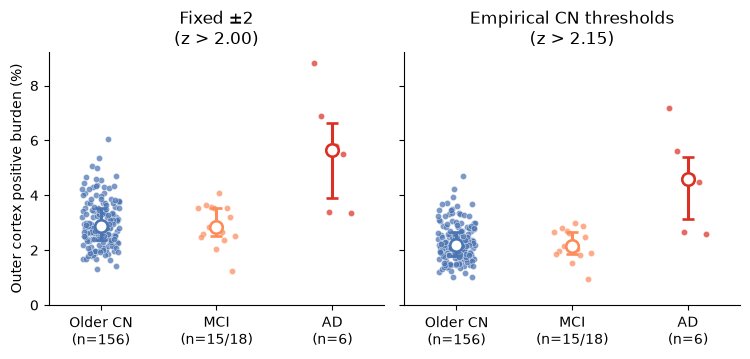

In [19]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import norm

stage2_models = {
    "Age + sex + thickness": "age_sex_thickness_z.npy",
    "Age + sex": "age_sex_z.npy",
}
group_order = ["Older CN", "MCI", "AD"]
plot_colors = {"Older CN": "#4B74B2", "MCI": "#FC8C5A", "AD": "#DB3124"}

stage2_participants = (
    pd.read_csv(
        run_dir / "participants.csv",
        usecols=["scoring_row_index", "diagnosis_at_scan", "model_role"],
    )
    .sort_values("scoring_row_index")
    .reset_index(drop=True)
)
if not np.array_equal(stage2_participants["scoring_row_index"], np.arange(180)):
    raise ValueError("Expected scoring row indices 0–179 exactly once.")

diagnosis = (
    stage2_participants["diagnosis_at_scan"]
    .astype("string").str.strip().str.upper()
)
participant_groups = diagnosis.map({
    "NORMAL": "Older CN", "CN": "Older CN", "MCI": "MCI", "AD": "AD",
})
expected_counts = {"Older CN": 156, "MCI": 18, "AD": 6}
if participant_groups.value_counts().to_dict() != expected_counts:
    raise ValueError(f"Unexpected diagnosis counts: {diagnosis.value_counts().to_dict()}")

cn_mask = participant_groups.eq("Older CN").to_numpy(dtype=bool)
cn_role_mask = (
    stage2_participants["model_role"]
    .eq("older_cn_target").to_numpy(dtype=bool)
)
if not np.array_equal(cn_mask, cn_role_mask):
    raise ValueError("Older CN diagnoses and model roles do not match.")

stage2_shape = (180, 4687, 21)
outer_depths = slice(0, 7)

def load_stage2_array(filename):
    array = np.load(run_dir / filename, mmap_mode="r", allow_pickle=False)
    if array.shape not in {stage2_shape, (180, 4687 * 21)}:
        raise ValueError(f"Unexpected shape for {filename}: {array.shape}")
    return array.reshape(stage2_shape)

all_depth_scores = {
    model: load_stage2_array(filename)
    for model, filename in stage2_models.items()
}
outer_scores = {
    model: scores[:, :, outer_depths]
    for model, scores in all_depth_scores.items()
}
outer_valid = {
    model: np.isfinite(scores) for model, scores in outer_scores.items()
}
shared_outer_valid = np.logical_and.reduce(list(outer_valid.values()))
n_valid_outer = shared_outer_valid.sum(axis=(1, 2))

fixed_label = "Fixed ±2"
empirical_label = "Empirical CN thresholds"
tail_probability = norm.sf(2)
threshold_rows = []
burden_tables = []

for model, scores in outer_scores.items():
    cn_scores = scores[cn_mask][shared_outer_valid[cn_mask]]
    if cn_scores.size == 0:
        raise ValueError(f"No shared finite older CN scores for {model}.")

    lower, upper = np.quantile(
        cn_scores, [tail_probability, 1 - tail_probability]
    )
    threshold_rows.append({
        "Model": model,
        "Lower cutoff": lower,
        "Upper cutoff": upper,
        "CN lower tail (%)": 100 * np.mean(cn_scores < lower),
        "CN upper tail (%)": 100 * np.mean(cn_scores > upper),
    })

    for threshold_name, low, high in [
        (fixed_label, -2, 2),
        (empirical_label, lower, upper),
    ]:
        for direction, exceeds in [
            ("Positive", scores > high),
            ("Negative", scores < low),
        ]:
            counts = (shared_outer_valid & exceeds).sum(axis=(1, 2))
            burden_pct = np.divide(
                100.0 * counts,
                n_valid_outer,
                out=np.full(n_valid_outer.shape, np.nan),
                where=n_valid_outer > 0,
            )
            burden_tables.append(pd.DataFrame({
                "Scoring row": stage2_participants["scoring_row_index"],
                "Group": participant_groups,
                "Model": model,
                "Direction": direction,
                "Threshold": threshold_name,
                "Valid outer scores": n_valid_outer,
                "Burden (%)": burden_pct,
            }))

threshold_table = pd.DataFrame(threshold_rows).set_index("Model")
empirical_burden = pd.concat(burden_tables, ignore_index=True)
empirical_summary = empirical_burden.groupby(
    ["Model", "Direction", "Threshold", "Group"], sort=False
)["Burden (%)"].agg(
    n_total="size",
    n_scored="count",
    median="median",
    q25=lambda values: values.quantile(.25),
    q75=lambda values: values.quantile(.75),
)

display(threshold_table.round(3))
display(empirical_summary.round(3))

main_model = "Age + sex + thickness"
plot_data = empirical_burden.loc[
    empirical_burden["Model"].eq(main_model)
    & empirical_burden["Direction"].eq("Positive")
]

# Keep each participant's horizontal offset fixed across both panels.
rng = np.random.default_rng(20261111)
offset_by_row = pd.Series(0.0, index=stage2_participants["scoring_row_index"])
for group_name in group_order:
    rows = stage2_participants.loc[
        participant_groups.eq(group_name) & (n_valid_outer > 0),
        "scoring_row_index",
    ]
    offsets = np.linspace(-.16, .16, len(rows)) if len(rows) > 1 else np.zeros(len(rows))
    rng.shuffle(offsets)
    offset_by_row.loc[rows] = offsets

fig, axes = plt.subplots(1, 2, figsize=(7.6, 3.7), sharey=True)

for ax, threshold_name in zip(axes, [fixed_label, empirical_label]):
    tick_labels = []
    for x, group_name in enumerate(group_order):
        group_data = plot_data.loc[
            plot_data["Threshold"].eq(threshold_name)
            & plot_data["Group"].eq(group_name)
        ]
        scored = group_data.dropna(subset=["Burden (%)"])
        n_scored, n_total = len(scored), len(group_data)
        count_label = str(n_scored)
        tick_labels.append(f"{group_name}\n(n={count_label})")
        if scored.empty:
            continue

        values = scored["Burden (%)"].to_numpy()
        offsets = scored["Scoring row"].map(offset_by_row).to_numpy()
        color = plot_colors[group_name]
        ax.scatter(
            x + offsets, values, s=20, alpha=.72, color=color,
            edgecolors="white", linewidth=.35, zorder=2,
        )
        q25, median, q75 = np.quantile(values, [.25, .50, .75])
        ax.errorbar(
            x, median, yerr=[[median - q25], [q75 - median]],
            fmt="o", color=color, mfc="white", mec=color,
            mew=1.9, capsize=4, capthick=2.2,
            markersize=9, linewidth=2.2, zorder=5,
        )

    cutoff = 2 if threshold_name == fixed_label else threshold_table.loc[
        main_model, "Upper cutoff"
    ]
    ax.set_title(f"{threshold_name}\n(z > {cutoff:.2f})")
    ax.set_xticks(range(len(group_order)), tick_labels)
    ax.set_xlim(-.45, 2.45)
    ax.set_ylim(bottom=0)
    if callable(globals().get("style_axes")):
        style_axes(ax)
    else:
        ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("Outer cortex positive burden (%)")
fig.tight_layout()
plt.show()

In [ ]:
# Standalone audit of all 180 scoring rows, using outer depths 0:7.
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

audit_run = Path('/mnt/newStor/paros/paros_WORK/xintong/code/cortical_trajectory_analysis/analysis_results/figure6_new/outputs/warped_delta_382DBdHx')
audit_roster = pd.read_csv(audit_run / 'participants.csv').sort_values('scoring_row_index').reset_index(drop=True)
assert np.array_equal(audit_roster.scoring_row_index.to_numpy(), np.arange(180))
audit_groups = audit_roster.diagnosis_at_scan.astype('string').str.strip().str.upper()
audit_models = {'Age + sex + thickness': 'age_sex_thickness_z.npy', 'Age + sex': 'age_sex_z.npy'}
audit_shared = np.ones((180,4687,7), dtype=bool)
for audit_filename in audit_models.values():
    audit_array = np.load(audit_run / audit_filename, mmap_mode='r', allow_pickle=False)
    if audit_array.shape not in ((180,4687,21),(180,98427)):
        raise ValueError(f'Unexpected score shape: {audit_array.shape}')
    audit_shared &= np.isfinite(audit_array.reshape(180,4687,21)[:,:,:7])

mci_missing = audit_groups.eq("MCI").to_numpy(dtype=bool) & ~audit_shared.any(axis=(1, 2))
missing_rows = np.flatnonzero(mci_missing)

metadata = pd.read_csv(
    audit_run / "participants.csv",
    usecols=["scoring_row_index", "subject_id", "actual_age", "SUBJECT_SEX"],
    dtype={"subject_id": "string"},
).set_index("scoring_row_index")

audit = metadata.loc[missing_rows].copy()
audit["Shared valid outer z"] = audit_shared[missing_rows].sum(axis=(1, 2))

for model, filename in audit_models.items():
    z = np.load(audit_run / filename, mmap_mode="r", allow_pickle=False)
    z_selected = z.reshape(180, 4687, 21)[missing_rows]
    audit[f"{model} | valid outer z"] = np.isfinite(z_selected[:, :, :7]).sum(axis=(1, 2))
    audit[f"{model} | valid z at all depths"] = np.isfinite(z_selected).sum(axis=(1, 2))

delta_path = audit_run / "delta_md.npy"
if delta_path.is_file():
    delta = np.load(delta_path, mmap_mode="r", allow_pickle=False)
    if delta.shape not in {(180, 4687, 21), (180, 4687 * 21)}:
        raise ValueError(f"Unexpected delta MD shape: {delta.shape}")
    delta_selected = delta.reshape(180, 4687, 21)[missing_rows]
    audit["Valid outer delta MD"] = np.isfinite(delta_selected[:, :, :7]).sum(axis=(1, 2))
    audit["Valid delta MD at all depths"] = np.isfinite(delta_selected).sum(axis=(1, 2))
else:
    print(f"Delta MD array not found: {delta_path}")

display(audit)

In [22]:
%pip install statsmodels

  Using cached patsy-1.0.3-py2.py3-none-any.whl.metadata (3.7 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 5.2 MB/s  0:00:02 eta 0:00:01
Using cached patsy-1.0.3-py2.py3-none-any.whl (233 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [statsmodels] [statsmodels]
Note: you may need to restart the kernel to use updated packages.


,Total,With burden,Analyzed
diagnosis,,,
Older CN,156,156,156
MCI,18,15,15
AD,6,6,6


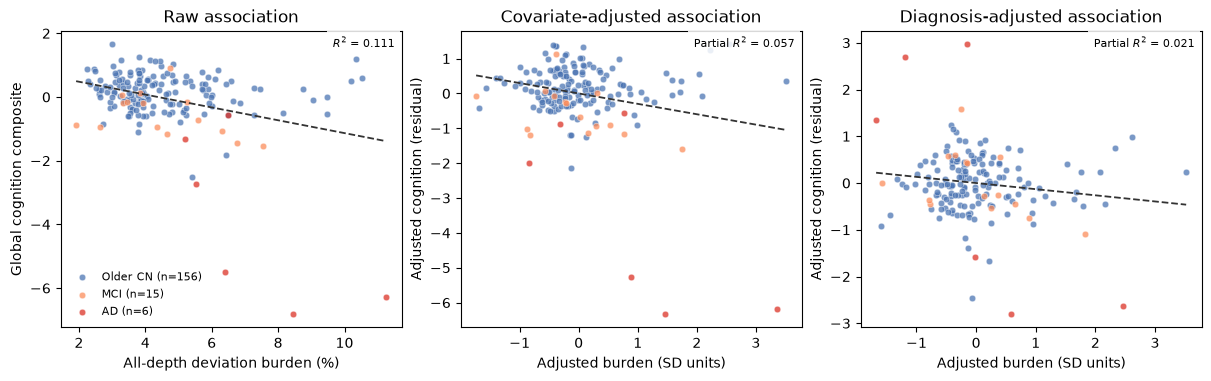

,Model,N,Cognition difference per 1 SD higher burden,95% CI lower,95% CI upper,p value,Model R²,Burden partial R²
0,Raw association,177,-0.3461,-0.6798,-0.0124,0.0422,0.1109,0.1109
1,Covariate-adjusted association,177,-0.2981,-0.7343,0.1381,0.1792,0.1269,0.0573
2,Diagnosis-adjusted association,177,-0.1314,-0.3391,0.0763,0.2135,0.5513,0.0214


In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from IPython.display import display

run_dir = Path(
    "/mnt/newStor/paros/paros_WORK/xintong/code/cortical_trajectory_analysis"
    "/analysis_results/figure6_new/outputs/warped_delta_382DBdHx"
)

group_order = ["Older CN", "MCI", "AD"]
plot_colors = {
    "Older CN": "#4B74B2",
    "MCI": "#FC8C5A",
    "AD": "#DB3124",
}

# Align participant metadata to the score array.
columns = [
    "scoring_row_index", "subject_id", "diagnosis_at_scan",
    "actual_age", "SUBJECT_SEX", "global_cognition",
]
cognition_data = (
    pd.read_csv(run_dir / "participants.csv", usecols=columns)
    .sort_values("scoring_row_index")
    .reset_index(drop=True)
)

z = np.load(run_dir / "age_sex_thickness_z.npy", mmap_mode="r", allow_pickle=False)
if z.shape not in {(180, 4687, 21), (180, 4687 * 21)}:
    raise ValueError(f"Unexpected score array shape: {z.shape}")
if not np.array_equal(cognition_data["scoring_row_index"], np.arange(z.shape[0])):
    raise ValueError("Participant rows do not match the score array.")
if cognition_data["subject_id"].isna().any() or cognition_data["subject_id"].duplicated().any():
    raise ValueError("Expected one row per participant with a unique subject ID.")

diagnosis = cognition_data["diagnosis_at_scan"].astype("string").str.strip().str.upper()
cognition_data["diagnosis"] = diagnosis.map({
    "NORMAL": "Older CN", "CN": "Older CN", "MCI": "MCI", "AD": "AD",
})
if cognition_data["diagnosis"].value_counts().to_dict() != {
    "Older CN": 156, "MCI": 18, "AD": 6,
}:
    raise ValueError("Unexpected diagnosis labels or group counts.")

# Use the finite scores from the thickness-adjusted model as the denominator.
flat_z = z.reshape(z.shape[0], -1)
finite = np.isfinite(flat_z)
n_valid = finite.sum(axis=1)
n_outliers = (finite & ((flat_z < -2) | (flat_z > 2))).sum(axis=1)

cognition_data["burden_pct"] = np.divide(
    100.0 * n_outliers,
    n_valid,
    out=np.full(len(n_valid), np.nan),
    where=n_valid > 0,
)
cognition_data["score_coverage"] = n_valid / flat_z.shape[1]
cognition_data["has_burden"] = n_valid > 0

for column in ["actual_age", "global_cognition"]:
    cognition_data[column] = pd.to_numeric(
        cognition_data[column], errors="coerce"
    ).replace([np.inf, -np.inf], np.nan)

cognition_data["sex"] = (
    cognition_data["SUBJECT_SEX"].astype("string").str.strip()
    .replace("", pd.NA).astype(object)
)

# Use one complete-case sample in every panel.
required = ["burden_pct", "global_cognition", "actual_age", "sex", "diagnosis"]
cognition_data["included"] = cognition_data[required].notna().all(axis=1)
sample_counts = (
    cognition_data.groupby("diagnosis")
    .agg(
        Total=("included", "size"),
        **{"With burden": ("has_burden", "sum"), "Analyzed": ("included", "sum")},
    )
    .reindex(group_order)
)
display(sample_counts)

analysis = cognition_data.loc[cognition_data["included"]].copy()
burden_mean = analysis["burden_pct"].mean()
burden_sd = analysis["burden_pct"].std(ddof=1)
if not np.isfinite(burden_sd) or burden_sd <= 0:
    raise ValueError("The complete-case sample has insufficient burden variation.")

analysis["burden_sd"] = (analysis["burden_pct"] - burden_mean) / burden_sd

panel_specs = [
    ("Raw association", ""),
    ("Covariate-adjusted association", "actual_age + C(sex) + score_coverage"),
    (
        "Diagnosis-adjusted association",
        "actual_age + C(sex) + score_coverage + C(diagnosis)",
    ),
]

fig, axes = plt.subplots(1, 3, figsize=(12, 3.7), layout="constrained")
results = []

for ax, (title, adjustment) in zip(axes, panel_specs):
    formula = "global_cognition ~ burden_sd"
    if adjustment:
        formula += f" + {adjustment}"

    fit = smf.ols(formula, data=analysis, missing="raise").fit(
        cov_type="HC3", use_t=True
    )
    design = fit.model.exog
    if np.linalg.matrix_rank(design) < design.shape[1] or fit.df_resid <= 0:
        raise ValueError(f"Insufficient independent variation for {title}.")

    beta = fit.params["burden_sd"]
    ci_low, ci_high = fit.conf_int().loc["burden_sd"]
    results.append({
        "Model": title,
        "N": int(fit.nobs),
        "Cognition difference per 1 SD higher burden": beta,
        "95% CI lower": ci_low,
        "95% CI upper": ci_high,
        "p value": fit.pvalues["burden_sd"],
        "Model R²": fit.rsquared,
    })

    if adjustment:
        x = smf.ols(f"burden_sd ~ {adjustment}", data=analysis).fit().resid
        y = smf.ols(f"global_cognition ~ {adjustment}", data=analysis).fit().resid
        x_grid = np.linspace(x.min(), x.max(), 100)
        y_fit = beta * x_grid
        xlabel = "Adjusted burden (SD units)"
        ylabel = "Adjusted cognition (residual)"
    else:
        x = analysis["burden_pct"]
        y = analysis["global_cognition"]
        x_grid = np.linspace(x.min(), x.max(), 100)
        y_fit = fit.params["Intercept"] + beta * (x_grid - burden_mean) / burden_sd
        xlabel = "All-depth deviation burden (%)"
        ylabel = "Global cognition composite"

    for group_name in group_order:
        mask = analysis["diagnosis"].eq(group_name)
        ax.scatter(
            x.loc[mask], y.loc[mask],
            s=22, alpha=.74, color=plot_colors[group_name],
            edgecolors="white", linewidth=.35,
            label=f"{group_name} (n={mask.sum()})", zorder=2,
        )
    ax.plot(x_grid, y_fit, "--", color="#333333", linewidth=1.3, zorder=3)

    if adjustment:
        plot_r2 = np.corrcoef(x, y)[0, 1] ** 2
        r2_label = f"Partial $R^2$ = {plot_r2:.3f}"
    else:
        plot_r2 = fit.rsquared
        r2_label = f"$R^2$ = {plot_r2:.3f}"


    results[-1]["Burden partial R²"] = plot_r2

    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)

axes[0].legend(frameon=False, fontsize=8)
plt.show()

cognition_results = pd.DataFrame(results)
display(cognition_results.round(4))

## Full-depth bilateral empirical-threshold statistics
Thickness-adjusted Stage 2 z-scores, all 21 depths. All three figures use z < −1.812082 or z > 2.191503, with each participant’s finite thickness-model positions as denominator. These older-CN empirical cutoffs were estimated on the shared finite positions of both models; they are fixed here. Group points show median and IQR; group differences show 10,000 participant-bootstrap 95% CIs (fixed cutoffs, not re-estimated in bootstrap). Cognition uses the same complete-case sample and age, sex, full-depth score-coverage adjustment, then diagnosis. Empirical calibration is descriptive and uses the same CN cohort.


In [ ]:
# Full-depth bilateral empirical burden: self-contained input alignment.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

emp_run = Path('/mnt/newStor/paros/paros_WORK/xintong/code/cortical_trajectory_analysis/analysis_results/figure6_new/outputs/warped_delta_382DBdHx')
emp_export = emp_run / 'calibration_figures/full_depth_empirical_bilateral'
emp_export.mkdir(parents=True, exist_ok=True)
EMP_LOWER, EMP_UPPER = -1.812082, 2.191503
emp_meta = pd.read_csv(emp_run / 'participants.csv').sort_values('scoring_row_index').reset_index(drop=True)
assert np.array_equal(emp_meta.scoring_row_index.to_numpy(), np.arange(180))
assert emp_meta.subject_id.nunique() == 180
emp_groups = emp_meta.diagnosis_at_scan.astype('string').str.strip().str.upper().map({'NORMAL':'Older CN', 'CN':'Older CN', 'MCI':'MCI', 'AD':'AD'})
emp_group_order = ['Older CN', 'MCI', 'AD']
emp_colors = {'Older CN':'#4B74B2', 'MCI':'#FC8C5A', 'AD':'#DB3124'}
emp_z = np.load(emp_run / 'age_sex_thickness_z.npy', mmap_mode='r', allow_pickle=False)
assert emp_z.shape in ((180, 4687, 21), (180, 98427))
emp_flat = emp_z.reshape(180, 98427)
# Use thickness-model finite positions for both burden and cognition.
emp_finite = np.isfinite(emp_flat)
emp_valid = emp_finite.sum(axis=1)
emp_count = (emp_finite & ((emp_flat < EMP_LOWER) | (emp_flat > EMP_UPPER))).sum(axis=1)
emp_burden = np.divide(100. * emp_count, emp_valid, out=np.full(180, np.nan), where=emp_valid > 0)
emp_subjects = pd.DataFrame({'scoring_row_index':emp_meta.scoring_row_index, 'subject_id':emp_meta.subject_id, 'Group':emp_groups, 'Valid positions':emp_valid, 'Bilateral count':emp_count, 'Burden (%)':emp_burden})
emp_subjects['Depths'] = '0:21'
emp_subjects['Lower cutoff'] = EMP_LOWER
emp_subjects['Upper cutoff'] = EMP_UPPER
assert emp_subjects.dropna(subset=['Burden (%)']).Group.value_counts().to_dict() == {'Older CN':156, 'MCI':15, 'AD':6}
emp_subjects.to_csv(emp_export / 'full_depth_empirical_bilateral_subjects.csv', index=False)
emp_summary = emp_subjects.groupby('Group')['Burden (%)'].agg(n='count', median='median', q25=lambda v:v.quantile(.25), q75=lambda v:v.quantile(.75)).reindex(emp_group_order)
emp_summary.to_csv(emp_export / 'full_depth_empirical_bilateral_summary.csv')
# Fixed and empirical bilateral burden on identical full-depth denominators.
fixed_count = (emp_finite & ((emp_flat < -2) | (emp_flat > 2))).sum(axis=1)
fixed_subjects = emp_subjects.copy()
fixed_subjects['Bilateral count'] = fixed_count
fixed_subjects['Burden (%)'] = np.divide(100.*fixed_count, emp_valid, out=np.full(180,np.nan), where=emp_valid>0)
fixed_subjects['Lower cutoff'], fixed_subjects['Upper cutoff'] = -2., 2.
comparison_tables = {'Fixed ±2':fixed_subjects, 'Empirical CN thresholds':emp_subjects}
pd.concat([t.assign(Threshold=k) for k,t in comparison_tables.items()],ignore_index=True).to_csv(emp_export / 'full_depth_fixed_vs_empirical_subjects.csv',index=False)
fig_emp_groups, emp_axes = plt.subplots(1,2,figsize=(7.6,3.7),sharey=True)
rng_emp_jitter = np.random.default_rng(20261111)
emp_offsets = {}
for group in emp_group_order:
    v = emp_subjects.loc[emp_subjects.Group.eq(group),'Burden (%)'].dropna()
    offset=np.linspace(-.16,.16,len(v));rng_emp_jitter.shuffle(offset)
    emp_offsets[group]=offset
for ax, (threshold,table) in zip(emp_axes,comparison_tables.items()):
    tick_labels=[]
    for i,group in enumerate(emp_group_order):
        v=table.loc[table.Group.eq(group),'Burden (%)'].dropna().to_numpy()
        color=emp_colors[group]
        tick_labels.append(f'{group}\n(n={len(v)})')
        ax.scatter(i+emp_offsets[group],v,s=20,alpha=.72,color=color,edgecolors='white',linewidth=.35,zorder=2)
        lo,med,hi=np.quantile(v,[.25,.5,.75])
        ax.errorbar(i,med,yerr=[[med-lo],[hi-med]],fmt='o',color=color,mfc='white',mew=1.9,markersize=9,capsize=4,capthick=2.2,linewidth=2.2,zorder=5)
    subtitle='(z < −2.00 or z > 2.00)' if threshold=='Fixed ±2' else f'(z < {EMP_LOWER:.3f} or z > {EMP_UPPER:.3f})'
    ax.set(title=threshold+'\n'+subtitle,xticks=range(3),xticklabels=tick_labels,xlim=(-.45,2.45),ylim=(0,None))
    ax.spines[['top','right']].set_visible(False)
emp_axes[0].set_ylabel('Full-depth bilateral burden (%)')
fig_emp_groups.tight_layout()
for ext in ['png','pdf']:
    fig_emp_groups.savefig(emp_export / f'full_depth_empirical_bilateral_groups.{ext}',dpi=300,bbox_inches='tight')
display(emp_summary)
plt.show()


In [ ]:
# Fixed versus empirical: participant bootstrap with fixed cutoffs.
rng_emp_boot=np.random.default_rng(20261111)
emp_diffs=[]
for threshold,table in comparison_tables.items():
    cn=table.loc[table.Group.eq('Older CN'),'Burden (%)'].dropna().to_numpy()
    for group in ['MCI','AD']:
        patient=table.loc[table.Group.eq(group),'Burden (%)'].dropna().to_numpy()
        estimate=np.median(patient)-np.median(cn)
        boot=np.median(rng_emp_boot.choice(patient,(10000,len(patient)),replace=True),axis=1)-np.median(rng_emp_boot.choice(cn,(10000,len(cn)),replace=True),axis=1)
        lo,hi=np.quantile(boot,[.025,.975])
        emp_diffs.append({'Threshold':threshold,'Comparison':group+' − CN','Median difference (pp)':estimate,'CI lower':lo,'CI upper':hi,'N patient':len(patient),'N CN':len(cn),'Bootstrap replicates':10000,'Seed':20261111})
emp_differences=pd.DataFrame(emp_diffs)
fig_emp_diff,ax_emp_diff=plt.subplots(figsize=(7,3.3),layout='constrained')
for j,(threshold,color) in enumerate(zip(comparison_tables,['#4B74B2','#FC8C5A'])):
    sub=emp_differences.loc[emp_differences.Threshold.eq(threshold)].reset_index(drop=True)
    for i,row in sub.iterrows():
        v=row['Median difference (pp)']
        ax_emp_diff.errorbar(v,i+(j-.5)*.24,xerr=[[v-row['CI lower']],[row['CI upper']-v]],fmt='o',color=color,mfc='white',mew=1.8,capsize=4,linewidth=2,label=threshold if i==0 else None)
ax_emp_diff.axvline(0,ls=':',color='.6')
ax_emp_diff.set(yticks=[0,1],yticklabels=['MCI − CN','AD − CN'],xlabel='Difference in median full-depth bilateral burden\n(percentage points)',title='Group differences',ylim=(1.45,-.45))
ax_emp_diff.spines[['top','right','left']].set_visible(False)
ax_emp_diff.legend(frameon=False,loc='upper right',fontsize=8)
for ext in ['png','pdf']:
    fig_emp_diff.savefig(emp_export / f'full_depth_empirical_bilateral_differences.{ext}',dpi=300,bbox_inches='tight')
emp_differences.to_csv(emp_export / 'full_depth_empirical_bilateral_differences.csv',index=False)
display(emp_differences)
plt.show()


### Earlier outer-layer fixed ±2 cognition analysis


In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from IPython.display import display

run_dir = Path(
    "/mnt/newStor/paros/paros_WORK/xintong/code/cortical_trajectory_analysis"
    "/analysis_results/figure6_new/outputs/warped_delta_382DBdHx"
)

group_order = ["Older CN", "MCI", "AD"]
plot_colors = {
    "Older CN": "#4B74B2",
    "MCI": "#FC8C5A",
    "AD": "#DB3124",
}

# Align participant metadata to the score array.
columns = [
    "scoring_row_index", "subject_id", "diagnosis_at_scan",
    "actual_age", "SUBJECT_SEX", "global_cognition",
]
cognition_data = (
    pd.read_csv(run_dir / "participants.csv", usecols=columns)
    .sort_values("scoring_row_index")
    .reset_index(drop=True)
)

z = np.load(run_dir / "age_sex_thickness_z.npy", mmap_mode="r", allow_pickle=False)
if z.shape not in {(180, 4687, 21), (180, 4687 * 21)}:
    raise ValueError(f"Unexpected score array shape: {z.shape}")
if not np.array_equal(cognition_data["scoring_row_index"], np.arange(z.shape[0])):
    raise ValueError("Participant rows do not match the score array.")
if cognition_data["subject_id"].isna().any() or cognition_data["subject_id"].duplicated().any():
    raise ValueError("Expected one row per participant with a unique subject ID.")

diagnosis = cognition_data["diagnosis_at_scan"].astype("string").str.strip().str.upper()
cognition_data["diagnosis"] = diagnosis.map({
    "NORMAL": "Older CN", "CN": "Older CN", "MCI": "MCI", "AD": "AD",
})
if cognition_data["diagnosis"].value_counts().to_dict() != {
    "Older CN": 156, "MCI": 18, "AD": 6,
}:
    raise ValueError("Unexpected diagnosis labels or group counts.")

# Use the finite scores from the thickness-adjusted model as the denominator.
flat_z = z.reshape(z.shape[0], 4687, 21)[:, :, :7].reshape(z.shape[0], -1)
finite = np.isfinite(flat_z)
n_valid = finite.sum(axis=1)
n_outliers = (finite & ((flat_z < -2) | (flat_z > 2))).sum(axis=1)

cognition_data["burden_pct"] = np.divide(
    100.0 * n_outliers,
    n_valid,
    out=np.full(len(n_valid), np.nan),
    where=n_valid > 0,
)
cognition_data["score_coverage"] = n_valid / flat_z.shape[1]
cognition_data["has_burden"] = n_valid > 0

for column in ["actual_age", "global_cognition"]:
    cognition_data[column] = pd.to_numeric(
        cognition_data[column], errors="coerce"
    ).replace([np.inf, -np.inf], np.nan)

cognition_data["sex"] = (
    cognition_data["SUBJECT_SEX"].astype("string").str.strip()
    .replace("", pd.NA).astype(object)
)

# Use one complete-case sample in every panel.
required = ["burden_pct", "global_cognition", "actual_age", "sex", "diagnosis"]
cognition_data["included"] = cognition_data[required].notna().all(axis=1)
sample_counts = (
    cognition_data.groupby("diagnosis")
    .agg(
        Total=("included", "size"),
        **{"With burden": ("has_burden", "sum"), "Analyzed": ("included", "sum")},
    )
    .reindex(group_order)
)
display(sample_counts)

analysis = cognition_data.loc[cognition_data["included"]].copy()
burden_mean = analysis["burden_pct"].mean()
burden_sd = analysis["burden_pct"].std(ddof=1)
if not np.isfinite(burden_sd) or burden_sd <= 0:
    raise ValueError("The complete-case sample has insufficient burden variation.")

analysis["burden_sd"] = (analysis["burden_pct"] - burden_mean) / burden_sd

panel_specs = [
    ("Raw association", ""),
    ("Covariate-adjusted association", "actual_age + C(sex) + score_coverage"),
    (
        "Diagnosis-adjusted association",
        "actual_age + C(sex) + score_coverage + C(diagnosis)",
    ),
]

fig, axes = plt.subplots(1, 3, figsize=(12, 3.7), layout="constrained")
results = []

for ax, (title, adjustment) in zip(axes, panel_specs):
    formula = "global_cognition ~ burden_sd"
    if adjustment:
        formula += f" + {adjustment}"

    fit = smf.ols(formula, data=analysis, missing="raise").fit(
        cov_type="HC3", use_t=True
    )
    design = fit.model.exog
    if np.linalg.matrix_rank(design) < design.shape[1] or fit.df_resid <= 0:
        raise ValueError(f"Insufficient independent variation for {title}.")

    beta = fit.params["burden_sd"]
    ci_low, ci_high = fit.conf_int().loc["burden_sd"]
    results.append({
        "Model": title,
        "N": int(fit.nobs),
        "Cognition difference per 1 SD higher burden": beta,
        "95% CI lower": ci_low,
        "95% CI upper": ci_high,
        "p value": fit.pvalues["burden_sd"],
        "Model R²": fit.rsquared,
    })

    if adjustment:
        x = smf.ols(f"burden_sd ~ {adjustment}", data=analysis).fit().resid
        y = smf.ols(f"global_cognition ~ {adjustment}", data=analysis).fit().resid
        x_grid = np.linspace(x.min(), x.max(), 100)
        y_fit = beta * x_grid
        xlabel = "Adjusted burden (SD units)"
        ylabel = "Adjusted cognition (residual)"
    else:
        x = analysis["burden_pct"]
        y = analysis["global_cognition"]
        x_grid = np.linspace(x.min(), x.max(), 100)
        y_fit = fit.params["Intercept"] + beta * (x_grid - burden_mean) / burden_sd
        xlabel = "Outer-layer deviation burden (%)"
        ylabel = "Global cognition composite"

    for group_name in group_order:
        mask = analysis["diagnosis"].eq(group_name)
        ax.scatter(
            x.loc[mask], y.loc[mask],
            s=22, alpha=.74, color=plot_colors[group_name],
            edgecolors="white", linewidth=.35,
            label=f"{group_name} (n={mask.sum()})", zorder=2,
        )
    ax.plot(x_grid, y_fit, "--", color="#333333", linewidth=1.3, zorder=3)

    if adjustment:
        plot_r2 = np.corrcoef(x, y)[0, 1] ** 2
        r2_label = f"Partial $R^2$ = {plot_r2:.3f}"
    else:
        plot_r2 = fit.rsquared
        r2_label = f"$R^2$ = {plot_r2:.3f}"


    results[-1]["Burden partial R²"] = plot_r2

    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)

axes[0].legend(frameon=False, fontsize=8, loc="lower left")
for ext in ["png", "pdf"]:
    fig.savefig(outer_export_dir / f"outer_cognition_associations.{ext}", dpi=300, bbox_inches="tight")
plt.show()

cognition_results = pd.DataFrame(results)
display(cognition_results.round(4))
cognition_results.to_csv(outer_export_dir / "outer_cognition_statistics.csv", index=False)
cognition_data.to_csv(outer_export_dir / "outer_cognition_subjects.csv", index=False)


## Full-depth cognition · bilateral empirical thresholds
z < −1.812082 or z > 2.191503; fixed model-specific finite-position denominator.


In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from IPython.display import display

run_dir = Path(
    "/mnt/newStor/paros/paros_WORK/xintong/code/cortical_trajectory_analysis"
    "/analysis_results/figure6_new/outputs/warped_delta_382DBdHx"
)

group_order = ["Older CN", "MCI", "AD"]
plot_colors = {
    "Older CN": "#4B74B2",
    "MCI": "#FC8C5A",
    "AD": "#DB3124",
}

# Align participant metadata to the score array.
columns = [
    "scoring_row_index", "subject_id", "diagnosis_at_scan",
    "actual_age", "SUBJECT_SEX", "global_cognition",
]
cognition_data = (
    pd.read_csv(run_dir / "participants.csv", usecols=columns)
    .sort_values("scoring_row_index")
    .reset_index(drop=True)
)

z = np.load(run_dir / "age_sex_thickness_z.npy", mmap_mode="r", allow_pickle=False)
if z.shape not in {(180, 4687, 21), (180, 4687 * 21)}:
    raise ValueError(f"Unexpected score array shape: {z.shape}")
if not np.array_equal(cognition_data["scoring_row_index"], np.arange(z.shape[0])):
    raise ValueError("Participant rows do not match the score array.")
if cognition_data["subject_id"].isna().any() or cognition_data["subject_id"].duplicated().any():
    raise ValueError("Expected one row per participant with a unique subject ID.")

diagnosis = cognition_data["diagnosis_at_scan"].astype("string").str.strip().str.upper()
cognition_data["diagnosis"] = diagnosis.map({
    "NORMAL": "Older CN", "CN": "Older CN", "MCI": "MCI", "AD": "AD",
})
if cognition_data["diagnosis"].value_counts().to_dict() != {
    "Older CN": 156, "MCI": 18, "AD": 6,
}:
    raise ValueError("Unexpected diagnosis labels or group counts.")

# Full-depth bilateral empirical thresholds; model-specific finite denominator.
EMP_LOWER, EMP_UPPER = -1.812082, 2.191503
emp_export = run_dir / "calibration_figures/full_depth_empirical_bilateral"
emp_export.mkdir(parents=True, exist_ok=True)
flat_z = z.reshape(z.shape[0], -1)
finite = np.isfinite(flat_z)
n_valid = finite.sum(axis=1)
n_outliers = (finite & ((flat_z < EMP_LOWER) | (flat_z > EMP_UPPER))).sum(axis=1)

cognition_data["burden_pct"] = np.divide(
    100.0 * n_outliers,
    n_valid,
    out=np.full(len(n_valid), np.nan),
    where=n_valid > 0,
)
cognition_data["score_coverage"] = n_valid / flat_z.shape[1]
cognition_data["has_burden"] = n_valid > 0

for column in ["actual_age", "global_cognition"]:
    cognition_data[column] = pd.to_numeric(
        cognition_data[column], errors="coerce"
    ).replace([np.inf, -np.inf], np.nan)

cognition_data["sex"] = (
    cognition_data["SUBJECT_SEX"].astype("string").str.strip()
    .replace("", pd.NA).astype(object)
)

# Use one complete-case sample in every panel.
required = ["burden_pct", "global_cognition", "actual_age", "sex", "diagnosis"]
cognition_data["included"] = cognition_data[required].notna().all(axis=1)
sample_counts = (
    cognition_data.groupby("diagnosis")
    .agg(
        Total=("included", "size"),
        **{"With burden": ("has_burden", "sum"), "Analyzed": ("included", "sum")},
    )
    .reindex(group_order)
)
display(sample_counts)

analysis = cognition_data.loc[cognition_data["included"]].copy()
burden_mean = analysis["burden_pct"].mean()
burden_sd = analysis["burden_pct"].std(ddof=1)
if not np.isfinite(burden_sd) or burden_sd <= 0:
    raise ValueError("The complete-case sample has insufficient burden variation.")

analysis["burden_sd"] = (analysis["burden_pct"] - burden_mean) / burden_sd

panel_specs = [
    ("Raw association", ""),
    ("Covariate-adjusted association", "actual_age + C(sex) + score_coverage"),
    (
        "Diagnosis-adjusted association",
        "actual_age + C(sex) + score_coverage + C(diagnosis)",
    ),
]

fig, axes = plt.subplots(1, 3, figsize=(12, 3.7), layout="constrained")
results = []

for ax, (title, adjustment) in zip(axes, panel_specs):
    formula = "global_cognition ~ burden_sd"
    if adjustment:
        formula += f" + {adjustment}"

    fit = smf.ols(formula, data=analysis, missing="raise").fit(
        cov_type="HC3", use_t=True
    )
    design = fit.model.exog
    if np.linalg.matrix_rank(design) < design.shape[1] or fit.df_resid <= 0:
        raise ValueError(f"Insufficient independent variation for {title}.")

    beta = fit.params["burden_sd"]
    ci_low, ci_high = fit.conf_int().loc["burden_sd"]
    results.append({
        "Model": title,
        "N": int(fit.nobs),
        "Cognition difference per 1 SD higher burden": beta,
        "95% CI lower": ci_low,
        "95% CI upper": ci_high,
        "p value": fit.pvalues["burden_sd"],
        "Model R²": fit.rsquared,
    })

    if adjustment:
        x = smf.ols(f"burden_sd ~ {adjustment}", data=analysis).fit().resid
        y = smf.ols(f"global_cognition ~ {adjustment}", data=analysis).fit().resid
        x_grid = np.linspace(x.min(), x.max(), 100)
        y_fit = beta * x_grid
        xlabel = "Adjusted burden (SD units)"
        ylabel = "Adjusted cognition (residual)"
    else:
        x = analysis["burden_pct"]
        y = analysis["global_cognition"]
        x_grid = np.linspace(x.min(), x.max(), 100)
        y_fit = fit.params["Intercept"] + beta * (x_grid - burden_mean) / burden_sd
        xlabel = "Full-depth bilateral empirical burden (%)"
        ylabel = "Global cognition composite"

    for group_name in group_order:
        mask = analysis["diagnosis"].eq(group_name)
        ax.scatter(
            x.loc[mask], y.loc[mask],
            s=22, alpha=.74, color=plot_colors[group_name],
            edgecolors="white", linewidth=.35,
            label=f"{group_name} (n={mask.sum()})", zorder=2,
        )
    ax.plot(x_grid, y_fit, "--", color="#333333", linewidth=1.3, zorder=3)

    if adjustment:
        plot_r2 = np.corrcoef(x, y)[0, 1] ** 2
        r2_label = f"Partial $R^2$ = {plot_r2:.3f}"
    else:
        plot_r2 = fit.rsquared
        r2_label = f"$R^2$ = {plot_r2:.3f}"


    results[-1]["Burden partial R²"] = plot_r2

    ax.text(.98, .98, r2_label, transform=ax.transAxes, ha="right", va="top", fontsize=8)
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)

axes[0].legend(frameon=False, fontsize=8, loc="lower left")
for ext in ["png", "pdf"]:
    fig.savefig(emp_export / f"full_depth_empirical_bilateral_cognition.{ext}", dpi=300, bbox_inches="tight")
plt.show()

cognition_results = pd.DataFrame(results)
display(cognition_results.round(4))
assert len(analysis) == 177
cognition_results['Depth range'] = '0:21'
cognition_results['Direction'] = 'Bilateral'
cognition_results['Lower cutoff'] = EMP_LOWER
cognition_results['Upper cutoff'] = EMP_UPPER
cognition_results.to_csv(emp_export / 'full_depth_empirical_bilateral_cognition_statistics.csv', index=False)
cognition_data.to_csv(emp_export / 'full_depth_empirical_bilateral_cognition_subjects.csv', index=False)


## Domain-specific cognition regressions

This analysis keeps the full-depth bilateral empirical-threshold burden fixed and replaces the global cognition outcome with each of the five precomputed cognitive-domain composites. Domain scores are standardized within each domain-specific complete-case sample so that coefficients are comparable. HC3 regressions use the same age, sex, score-coverage, and diagnosis adjustments as the global-cognition analysis. Holm correction is applied across the five domains separately within each adjustment family. This is a domain-wise association analysis, not cognitive clustering.

,Domain,Outcome column,Model,N,N Older CN,N MCI,N AD,Standardized domain difference per 1 SD higher burden,95% CI lower,95% CI upper,p value,Model R2,Holm-adjusted p value,Depth range,Direction,Lower cutoff,Upper cutoff
0,Memory,Memory_Composite,Raw association,176,155,15,6,-0.0736,-0.2903,0.1431,0.5035,0.0054,0.5035,0:21,Bilateral,-1.8121,2.1915
1,Memory,Memory_Composite,Covariate-adjusted association,176,155,15,6,-0.0238,-0.3240,0.2764,0.8757,0.0194,1.0000,0:21,Bilateral,-1.8121,2.1915
2,Memory,Memory_Composite,Diagnosis-adjusted association,176,155,15,6,0.0630,-0.1265,0.2525,0.5126,0.2791,1.0000,0:21,Bilateral,-1.8121,2.1915
3,Executive function,Executive_Function_Composite,Raw association,175,155,15,5,-0.3411,-0.5786,-0.1037,0.0051,0.1164,0.0256,0:21,Bilateral,-1.8121,2.1915
4,Executive function,Executive_Function_Composite,Covariate-adjusted association,175,155,15,5,-0.2268,-0.5415,0.0879,0.1567,0.1577,0.7163,0:21,Bilateral,-1.8121,2.1915
5,Executive function,Executive_Function_Composite,Diagnosis-adjusted association,175,155,15,5,-0.1280,-0.3099,0.0538,0.1665,0.4012,0.5469,0:21,Bilateral,-1.8121,2.1915
6,Processing speed,Processing_Speed_Composite,Raw association,177,156,15,6,-0.3019,-0.5660,-0.0377,0.0253,0.0911,0.1014,0:21,Bilateral,-1.8121,2.1915
7,Processing speed,Processing_Speed_Composite,Covariate-adjusted association,177,156,15,6,-0.2606,-0.6104,0.0892,0.1433,0.1251,0.7163,0:21,Bilateral,-1.8121,2.1915
8,Processing speed,Processing_Speed_Composite,Diagnosis-adjusted association,177,156,15,6,-0.1570,-0.3568,0.0428,0.1226,0.4826,0.5469,0:21,Bilateral,-1.8121,2.1915
9,Language,Language_Composite,Raw association,177,156,15,6,-0.1046,-0.2534,0.0442,0.1671,0.0109,0.3342,0:21,Bilateral,-1.8121,2.1915


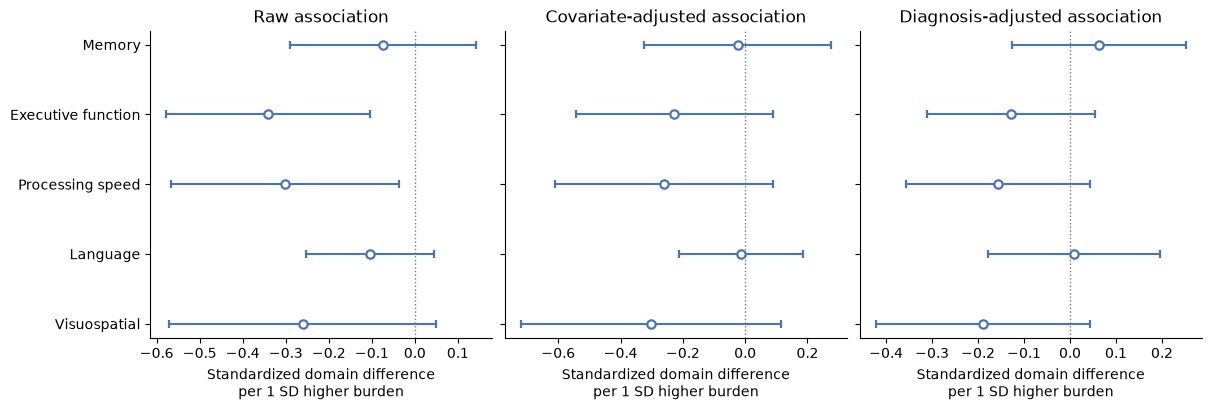

Saved domain regression outputs to: /mnt/newStor/paros/paros_WORK/xintong/code/cortical_trajectory_analysis/analysis_results/figure6_new/outputs/warped_delta_382DBdHx/calibration_figures/full_depth_empirical_bilateral/domain_cognition


In [110]:
# Domain-specific regressions using the fixed full-depth empirical burden.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from IPython.display import display
from statsmodels.stats.multitest import multipletests

domain_run = Path(
    "/mnt/newStor/paros/paros_WORK/xintong/code/cortical_trajectory_analysis"
    "/analysis_results/figure6_new/outputs/warped_delta_382DBdHx"
)
domain_export = domain_run / "calibration_figures/full_depth_empirical_bilateral/domain_cognition"
domain_export.mkdir(parents=True, exist_ok=True)
clinical_path = Path(
    "/mnt/newStor/paros/paros_WORK/xintong/data/"
    "ADRC_harmonized_metadata_QIAL_imaging_matches.csv"
)
EMP_LOW, EMP_HIGH = -1.812082, 2.191503

domain_columns = {
    "Memory": "Memory_Composite",
    "Executive function": "Executive_Function_Composite",
    "Processing speed": "Processing_Speed_Composite",
    "Language": "Language_Composite",
    "Visuospatial": "Visuospatial_Composite",
}
model_specs = {
    "Raw association": "",
    "Covariate-adjusted association": "actual_age + C(sex) + score_coverage",
    "Diagnosis-adjusted association": (
        "actual_age + C(sex) + score_coverage + C(diagnosis)"
    ),
}

# Reconstruct exactly the burden used in the preceding empirical-threshold analysis.
domain_meta = (
    pd.read_csv(domain_run / "participants.csv", dtype={"subject_id": str})
    .sort_values("scoring_row_index")
    .reset_index(drop=True)
)
if not np.array_equal(domain_meta["scoring_row_index"], np.arange(180)):
    raise ValueError("Expected scoring rows 0-179 exactly once.")
if domain_meta["subject_id"].isna().any() or domain_meta["subject_id"].duplicated().any():
    raise ValueError("Expected 180 unique participant IDs.")

domain_z = np.load(domain_run / "age_sex_thickness_z.npy", mmap_mode="r", allow_pickle=False)
if domain_z.shape not in {(180, 4687, 21), (180, 4687 * 21)}:
    raise ValueError(f"Unexpected score-array shape: {domain_z.shape}")
domain_flat = domain_z.reshape(180, -1)
domain_finite = np.isfinite(domain_flat)
domain_valid = domain_finite.sum(axis=1)
domain_outliers = (
    domain_finite & ((domain_flat < EMP_LOW) | (domain_flat > EMP_HIGH))
).sum(axis=1)
domain_meta["burden_pct"] = np.divide(
    100.0 * domain_outliers, domain_valid,
    out=np.full(180, np.nan), where=domain_valid > 0,
)
domain_meta["score_coverage"] = domain_valid / domain_flat.shape[1]

# Bring in the already-computed domain composites by the formal participant/visit key.
clinical_usecols = ["PTID_clean", "VISITNUM", *domain_columns.values()]
domain_clinical = pd.read_csv(
    clinical_path, usecols=clinical_usecols, low_memory=False,
    dtype={"PTID_clean": str, "VISITNUM": str},
)
if domain_clinical.duplicated(["PTID_clean", "VISITNUM"]).any():
    raise ValueError("Clinical participant/visit key is not unique.")
domain_data = domain_meta.merge(
    domain_clinical, left_on=["PTID_clean", "visit_id"],
    right_on=["PTID_clean", "VISITNUM"], how="left",
    validate="one_to_one",
)
domain_data["diagnosis"] = (
    domain_data["diagnosis_at_scan"].astype("string").str.strip().str.upper()
    .map({"NORMAL": "Older CN", "CN": "Older CN", "MCI": "MCI", "AD": "AD"})
)
domain_data["sex"] = (
    domain_data["SUBJECT_SEX"].astype("string").str.strip()
    .replace("", pd.NA).astype(object)
)
for column in ["actual_age", "burden_pct", "score_coverage", *domain_columns.values()]:
    domain_data[column] = pd.to_numeric(domain_data[column], errors="coerce").replace(
        [np.inf, -np.inf], np.nan
    )

domain_rows = []
for domain, outcome in domain_columns.items():
    required = [outcome, "burden_pct", "actual_age", "sex", "score_coverage", "diagnosis"]
    data = domain_data.loc[domain_data[required].notna().all(axis=1)].copy()
    outcome_sd = data[outcome].std(ddof=1)
    burden_sd = data["burden_pct"].std(ddof=1)
    if len(data) < 20 or not np.isfinite(outcome_sd) or outcome_sd <= 0:
        raise ValueError(f"Insufficient outcome data for {domain}.")
    if not np.isfinite(burden_sd) or burden_sd <= 0:
        raise ValueError(f"Insufficient burden variation for {domain}.")
    data["domain_z"] = (data[outcome] - data[outcome].mean()) / outcome_sd
    data["burden_sd"] = (data["burden_pct"] - data["burden_pct"].mean()) / burden_sd

    for model, adjustment in model_specs.items():
        formula = "domain_z ~ burden_sd" + (f" + {adjustment}" if adjustment else "")
        fit = smf.ols(formula, data=data, missing="raise").fit(cov_type="HC3", use_t=True)
        if np.linalg.matrix_rank(fit.model.exog) < fit.model.exog.shape[1] or fit.df_resid <= 0:
            raise ValueError(f"Rank-deficient model for {domain}: {model}.")
        ci_low, ci_high = fit.conf_int().loc["burden_sd"]
        domain_rows.append({
            "Domain": domain, "Outcome column": outcome, "Model": model,
            "N": int(fit.nobs),
            "N Older CN": int(data["diagnosis"].eq("Older CN").sum()),
            "N MCI": int(data["diagnosis"].eq("MCI").sum()),
            "N AD": int(data["diagnosis"].eq("AD").sum()),
            "Standardized domain difference per 1 SD higher burden": fit.params["burden_sd"],
            "95% CI lower": ci_low, "95% CI upper": ci_high,
            "p value": fit.pvalues["burden_sd"],
            "Model R2": fit.rsquared,
        })

domain_results = pd.DataFrame(domain_rows)
domain_results["Holm-adjusted p value"] = np.nan
for model in model_specs:
    idx = domain_results.index[domain_results["Model"].eq(model)]
    if len(idx) != len(domain_columns):
        raise ValueError(f"Expected five domain tests for {model}.")
    domain_results.loc[idx, "Holm-adjusted p value"] = multipletests(
        domain_results.loc[idx, "p value"], method="holm"
    )[1]

domain_results["Depth range"] = "0:21"
domain_results["Direction"] = "Bilateral"
domain_results["Lower cutoff"] = EMP_LOW
domain_results["Upper cutoff"] = EMP_HIGH
domain_results.to_csv(domain_export / "domain_regression_statistics.csv", index=False)
domain_data[[
    "scoring_row_index", "subject_id", "PTID_clean", "visit_id",
    "diagnosis", "actual_age", "sex", "burden_pct", "score_coverage",
    *domain_columns.values(),
]].to_csv(domain_export / "domain_regression_subjects.csv", index=False)

display(domain_results.round(4))

# Forest plot; coefficients are directly comparable because every domain is z-standardized.
fig, axes = plt.subplots(1, 3, figsize=(12, 4.0), sharey=True, layout="constrained")
domain_order = list(domain_columns)
for ax, model in zip(axes, model_specs):
    plot_data = domain_results.loc[domain_results["Model"].eq(model)].set_index("Domain").loc[domain_order]
    y = np.arange(len(domain_order))
    estimate = plot_data["Standardized domain difference per 1 SD higher burden"].to_numpy()
    lower = plot_data["95% CI lower"].to_numpy()
    upper = plot_data["95% CI upper"].to_numpy()
    ax.errorbar(estimate, y, xerr=[estimate - lower, upper - estimate], fmt="o",
                color="#4B74B2", mfc="white", mew=1.6, capsize=3)
    ax.axvline(0, color="#777777", linestyle=":", linewidth=1)
    ax.set(title=model, xlabel="Standardized domain difference\nper 1 SD higher burden",
           yticks=y, yticklabels=domain_order)
    ax.invert_yaxis()
    ax.spines[["top", "right"]].set_visible(False)
for ext in ["png", "pdf"]:
    fig.savefig(domain_export / f"domain_regression_forest.{ext}", dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved domain regression outputs to: {domain_export}")
